# Extract best-resolution tiles from DeepMoon train + val

For every tile we compute the effective km/pixel from `longlat_bounds` and `pix_distortion_coefficient`:

`(lon_range / 256) * 30.32 * cos(lat_centre) * distortion`

We scan train + val, combine, sort ascending by km/pixel, and pull the best 500 across both splits. `tiles[0]` has the finest resolution; `tiles[499]` has the coarsest of the 500 best.


In [1]:
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from contextlib import ExitStack


## 1. Config

In [2]:
TRAIN_IMAGES  = 'data/train_images.hdf5'
TRAIN_CRATERS = 'data/train_craters.hdf5'
VAL_IMAGES    = 'data/dev_images.hdf5'
VAL_CRATERS   = 'data/dev_craters.hdf5'

N_BEST      = 500     # total tiles to keep across both splits
MIN_CRATERS = 5       # skip tiles with fewer catalogue craters than this


## 2. Compute km/pixel for every tile

Moon: ≈ 30.32 km per degree of longitude at the equator; at latitude φ this shrinks by cos(φ). The per-tile distortion coefficient (typically 0.5–1.5) is the map-projection correction.

In [3]:
MOON_KM_PER_DEG = 30.32
TILE_SIZE       = 256

def km_per_pix(longlat_bounds, distortion):
    lon_min, lon_max, lat_min, lat_max = longlat_bounds
    lat_centre = (lat_min + lat_max) / 2
    lon_range  = lon_max - lon_min
    km_per_deg = MOON_KM_PER_DEG * np.cos(np.radians(lat_centre))
    return (lon_range / TILE_SIZE) * km_per_deg * float(distortion)

def scan_split(images_path, split_name):
    entries = []   # list of (km_per_px, split, orig_idx)
    with h5py.File(images_path, 'r') as fh:
        n = fh['input_images'].shape[0]
        ll_grp = fh['longlat_bounds']
        di_grp = fh['pix_distortion_coefficient']
        for i in range(n):
            ll = ll_grp[f'img_{i:05d}'][()]
            di = di_grp[f'img_{i:05d}'][()][0]
            entries.append((km_per_pix(ll, di), split_name, i))
    return entries


In [4]:
print('Scanning train ...')
entries = scan_split(TRAIN_IMAGES, 'train')
print('Scanning val   ...')
entries += scan_split(VAL_IMAGES, 'val')

entries.sort(key=lambda e: e[0])     # ascending → best resolution first

print(f'total tiles: {len(entries)}')
print(f'best  km/px: {entries[0][0]:.4f}')
print(f'worst km/px: {entries[-1][0]:.4f}')


Scanning train ...


Scanning val   ...


total tiles: 60000
best  km/px: 0.1200
worst km/px: 2.9993


## 3. Load the best 500 tiles

Files are opened once, tiles are pulled in the sorted order until we have `N_BEST` valid ones (i.e. with at least `MIN_CRATERS` catalogue craters).


In [5]:
with ExitStack() as stack:
    f_train = stack.enter_context(h5py.File(TRAIN_IMAGES, 'r'))
    f_val   = stack.enter_context(h5py.File(VAL_IMAGES,   'r'))
    c_train = stack.enter_context(pd.HDFStore(TRAIN_CRATERS, 'r'))
    c_val   = stack.enter_context(pd.HDFStore(VAL_CRATERS,   'r'))

    imgs    = {'train': f_train, 'val': f_val}
    craters = {'train': c_train, 'val': c_val}

    tiles = []
    for kmpp, split, idx in entries:
        if len(tiles) >= N_BEST:
            break
        key = f'img_{idx:05d}'
        cat = craters[split][f'/{key}']
        if len(cat) < MIN_CRATERS:
            continue
        f = imgs[split]
        tiles.append({
            'split'         : split,
            'orig_idx'      : int(idx),
            'dem'           : f['input_images'][idx],
            'mask'          : f['target_masks'][idx],
            'craters'       : cat,
            'km_per_px'     : float(kmpp),
            'longlat_bounds': f['longlat_bounds'][key][()],
            'distortion'    : float(f['pix_distortion_coefficient'][key][()][0]),
        })

print(f'extracted {len(tiles)} tiles')
print(f'  tiles[0]   → km/px {tiles[0]["km_per_px"]:.4f}   ({tiles[0]["split"]}, idx {tiles[0]["orig_idx"]})')
print(f'  tiles[-1]  → km/px {tiles[-1]["km_per_px"]:.4f}   ({tiles[-1]["split"]}, idx {tiles[-1]["orig_idx"]})')


extracted 500 tiles
  tiles[0]   → km/px 0.1243   (val, idx 20494)
  tiles[-1]  → km/px 0.2048   (train, idx 26362)


In [6]:
# tabular overview of all 500 tiles
overview = pd.DataFrame([{
    'rank'     : i,
    'split'    : t['split'],
    'orig_idx' : t['orig_idx'],
    'km_per_px': round(t['km_per_px'], 4),
    'craters'  : len(t['craters']),
    'lat_ctr'  : round((t['longlat_bounds'][2] + t['longlat_bounds'][3]) / 2, 2),
    'lon_ctr'  : round((t['longlat_bounds'][0] + t['longlat_bounds'][1]) / 2, 2),
} for i, t in enumerate(tiles)])
overview


,rank,split,orig_idx,km_per_px,craters,lat_ctr,lon_ctr
0,0,val,20494,0.1243,5,-58.75,-25.61
1,1,val,9664,0.1244,5,-58.79,-3.90
2,2,val,21528,0.1297,6,-58.27,41.39
3,3,train,9208,0.1300,5,-56.48,-159.93
4,4,train,1432,0.1309,5,58.14,-118.02
...,...,...,...,...,...,...,...
495,495,train,23626,0.2045,8,41.21,-167.58
496,496,train,22342,0.2047,6,-45.43,-131.27
497,497,train,8308,0.2047,10,41.70,-116.07
498,498,train,8606,0.2047,13,56.72,-173.83


## 4. Sanity check: best and coarsest of the 500

tiles[0]  (best): split=val  idx=20494  km/px=0.1243  craters=5


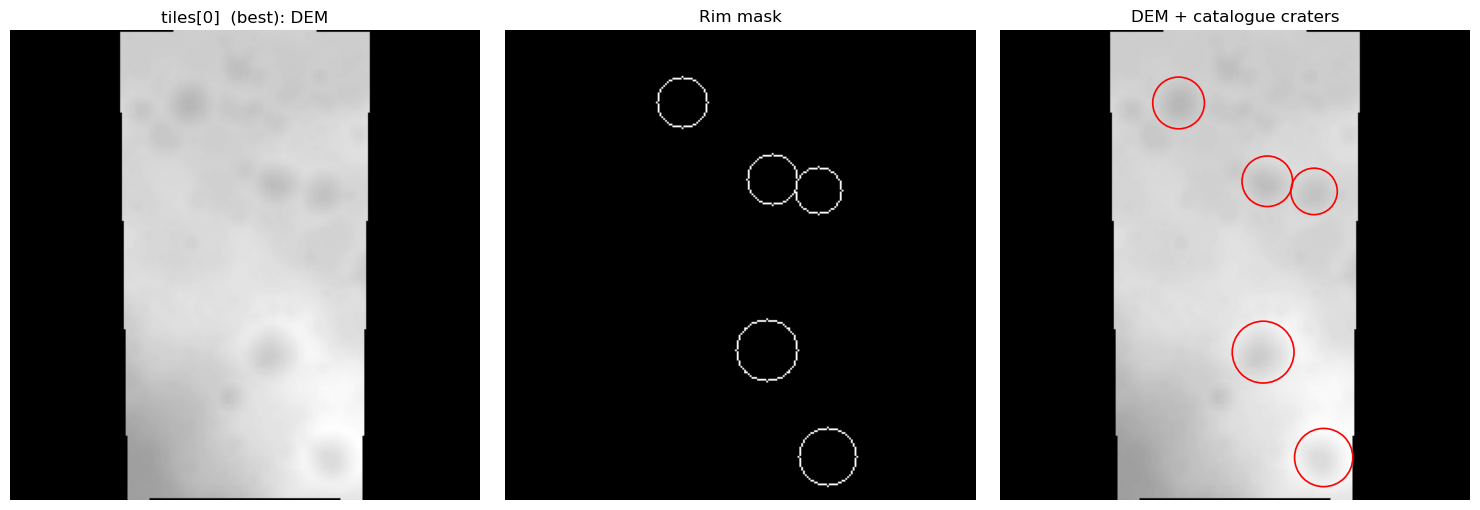

tiles[-1] (coarsest of the top 500): split=train  idx=26362  km/px=0.2048  craters=6


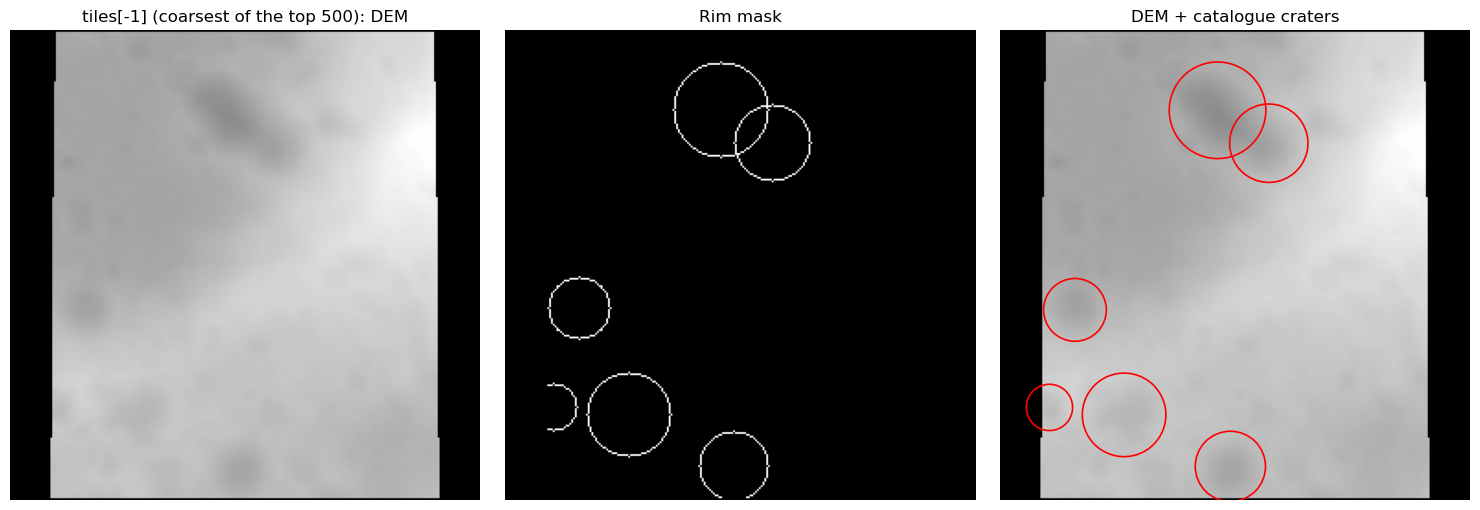

In [7]:
def show_tile(t, label):
    print(f"{label}: split={t['split']}  idx={t['orig_idx']}  km/px={t['km_per_px']:.4f}  craters={len(t['craters'])}")
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    ax[0].imshow(t['dem'], cmap='gray');  ax[0].set_title(f"{label}: DEM")
    ax[1].imshow(t['mask'], cmap='gray'); ax[1].set_title('Rim mask')
    ax[2].imshow(t['dem'], cmap='gray');  ax[2].set_title('DEM + catalogue craters')
    for _, c in t['craters'].iterrows():
        ax[2].add_patch(Circle((c['x'], c['y']), c['Diameter (pix)']/2,
                               fill=False, color='red', lw=1.2))
    for a in ax: a.axis('off')
    plt.tight_layout(); plt.show()

show_tile(tiles[0],   'tiles[0]  (best)')
show_tile(tiles[-1],  'tiles[-1] (coarsest of the top 500)')


## 5. Save the 500 tiles in the same format as the input

Two output files, mirroring the input structure exactly:

- **`best500_images.hdf5`**: `input_images` (N, 256, 256) uint8, `target_masks` (N, 256, 256) float, plus per-tile groups `longlat_bounds` and `pix_distortion_coefficient` keyed by `img_%05d`.
- **`best500_craters.hdf5`**: a `pd.HDFStore` with one crater-table DataFrame per tile, keyed by `img_%05d`.

Tiles are written in their new sorted order (0 = best resolution), so the `img_%05d` key in the output no longer refers to the original index. `orig_idx` and `split` are kept as extra columns in the crater tables so you can always trace a tile back.

In [8]:
OUT_IMAGES  = 'data/best500_images.hdf5'
OUT_CRATERS = 'data/best500_craters.hdf5'

N = len(tiles)
H, W = tiles[0]['dem'].shape

with h5py.File(OUT_IMAGES, 'w') as fh:
    # main image stacks, same dtype/shape convention as the DeepMoon files
    dem_stack  = fh.create_dataset('input_images', shape=(N, H, W), dtype=tiles[0]['dem'].dtype)
    mask_stack = fh.create_dataset('target_masks', shape=(N, H, W), dtype=tiles[0]['mask'].dtype)

    ll_grp = fh.create_group('longlat_bounds')
    di_grp = fh.create_group('pix_distortion_coefficient')

    for i, t in enumerate(tiles):
        key = f'img_{i:05d}'
        dem_stack[i]  = t['dem']
        mask_stack[i] = t['mask']
        ll_grp.create_dataset(key, data=np.asarray(t['longlat_bounds'], dtype=np.float64))
        di_grp.create_dataset(key, data=np.asarray([t['distortion']],   dtype=np.float64))

print(f'wrote {OUT_IMAGES}  ({N} tiles)')


wrote data/best500_images.hdf5  (500 tiles)


In [9]:
with pd.HDFStore(OUT_CRATERS, 'w') as store:
    for i, t in enumerate(tiles):
        key = f'img_{i:05d}'
        cat = t['craters'].copy()
        cat['orig_idx'] = t['orig_idx']   # keep provenance
        cat['split']    = t['split']      # 'train' or 'val'
        store.put(key, cat)

print(f'wrote {OUT_CRATERS}  ({N} crater tables)')


wrote data/best500_craters.hdf5  (500 crater tables)


## 6. Sanity check: reload from disk

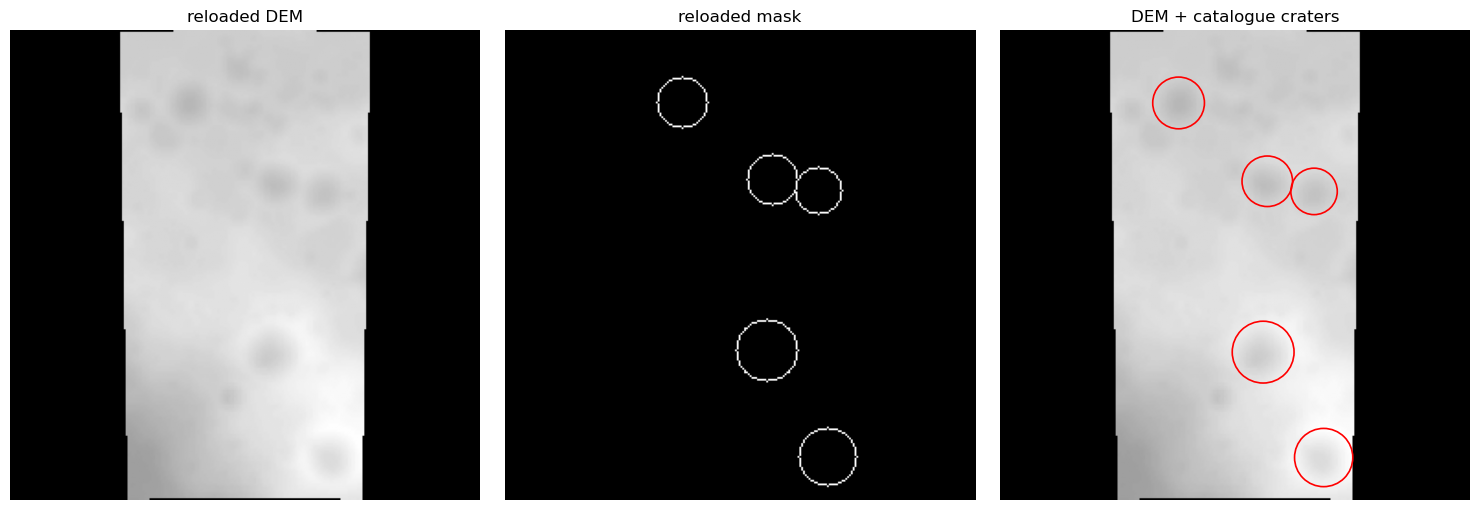

In [10]:
with h5py.File(OUT_IMAGES, 'r') as fh, pd.HDFStore(OUT_CRATERS, 'r') as store:
    j = 0
    dem  = fh['input_images'][j]
    mask = fh['target_masks'][j]
    ll   = fh['longlat_bounds'][f'img_{j:05d}'][()]
    di   = fh['pix_distortion_coefficient'][f'img_{j:05d}'][()][0]
    cat  = store[f'/img_{j:05d}']

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(dem, cmap='gray');  ax[0].set_title('reloaded DEM')
ax[1].imshow(mask, cmap='gray'); ax[1].set_title('reloaded mask')
ax[2].imshow(dem, cmap='gray');  ax[2].set_title('DEM + catalogue craters')
for _, c in cat.iterrows():
    ax[2].add_patch(Circle((c['x'], c['y']), c['Diameter (pix)']/2,
                           fill=False, color='red', lw=1.2))
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()